# S100A14–zinc: active six-temperature calorimetric inversion

## Problem
Recover binding enthalpy H, reference association constant K, effective concentration/site factor f and six dilution slopes/offsets from real GE ITC200 injection heats. These are standard-method estimates, not independent ground truth. All84injections are preserved;78nonfirst shots are fitted.

## Data
The original instrument-integrated author observations are reused unchanged. Native headers govern actual temperature and2mM zinc; historical introductory prose says200mM, a documented source discrepancy.

In [1]:
from pathlib import Path
import sys,time,numpy as np
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,ACQUISITION
from src.solvers import reconstruct,submission
from src.physics_model import predict,association_constants
from src.visualization import make_figures
import matplotlib.pyplot as plt
data=load_data(ROOT/'data/raw_data.npz')
print('Actual acquisition rows (Celsius,M,M,microlitre,R):');print(ACQUISITION)
print('Input shape:',data['heats'].shape)

Actual acquisition rows (Celsius,M,M,microlitre,R):
[[5.3330400e+00 1.1000000e-04 2.0000000e-03 2.0130000e+02 1.9872036e+00]
 [1.0006850e+01 1.1000000e-04 2.0000000e-03 2.0130000e+02 1.9872036e+00]
 [1.7130530e+01 1.1000000e-04 2.0000000e-03 2.0130000e+02 1.9872036e+00]
 [2.4996230e+01 1.1000000e-04 2.0000000e-03 2.0130000e+02 1.9872036e+00]
 [2.9997220e+01 1.1000000e-04 2.0000000e-03 2.0130000e+02 1.9872036e+00]
 [3.4999550e+01 1.1000000e-04 2.0000000e-03 2.0130000e+02 1.9872036e+00]]
Input shape: (6, 14)


## Physics

For shot-volume fraction products P, S=fS0P and L=L0(1−P) account for overflow. Complex concentration C solves C=K(S−C)(L−C); the smaller quadratic root respects mass conservation. Occupancy u=C/S determines injection heat q=V S(after) H Δu+m L(after)+c. V is in microlitres, concentrations in M and H in cal/mol, so q is microcal. Temperature obeys K(T)=Kref exp[−H/R(1/T−1/298.15)], with T in Kelvin and R=1.9872036cal/(mol K).

## Method

Run the author's published ML alternative, a shared15-parameter trust-region least-squares fit, with exactly the original initial point and effective factor bounds[.5,1.5]. A.1microcal uniform weight reproduces its numerical convention; it is not a measured noise calibration. There is no Bayesian posterior in this task. No stored output is substituted for the fresh reconstruction.

In [2]:
start=time.perf_counter()
fit=reconstruct(data)
runtime=time.perf_counter()-start
fresh=submission(fit,data)
assert fit.success
print('Full fresh reconstruction seconds:',runtime)
print('H,Kref,effective factor:',fit.x[:3])
print('Weighted least-squares cost:',fit.cost)
print('Local uncertainty diagnostic singular values:',np.linalg.svd(fit.jac*np.maximum(np.abs(fit.x),1),compute_uv=False))
print('Effective factor above1 represents concentration/site correction, not literal probability.')

Full fresh reconstruction seconds: 0.1602085999911651
H,Kref,effective factor: [-6.23431768e+03  9.05916715e+03  1.47189547e+00]
Weighted least-squares cost: 957.1665016422733
Local uncertainty diagnostic singular values: [1.51388698e+03 7.92358582e+02 6.62736588e+02 5.62726486e+02
 3.41824680e+02 2.68048565e+02 2.26180633e+02 1.42147010e+02
 8.86218027e+01 7.55366256e+01 6.61584253e+01 3.46605487e+01
 2.13582058e+01 7.82308510e+00 9.92257180e-01]
Effective factor above1 represents concentration/site correction, not literal probability.


## Results
The following figures compare fresh local ML with the separately reproduced original author ML on exactly these observations. The excluded first shots remain visible. The paired bars use the same physical RMSE formula for both methods; no historical paper metric is relabeled as a fresh result.

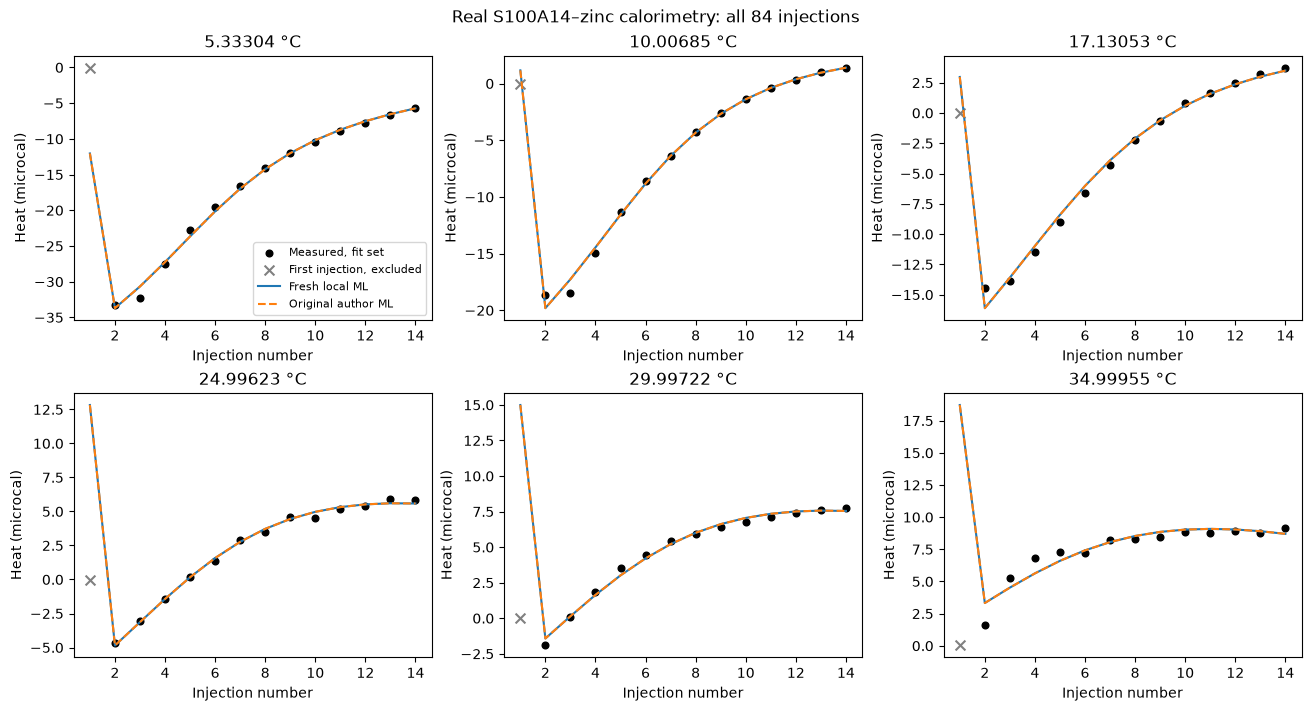

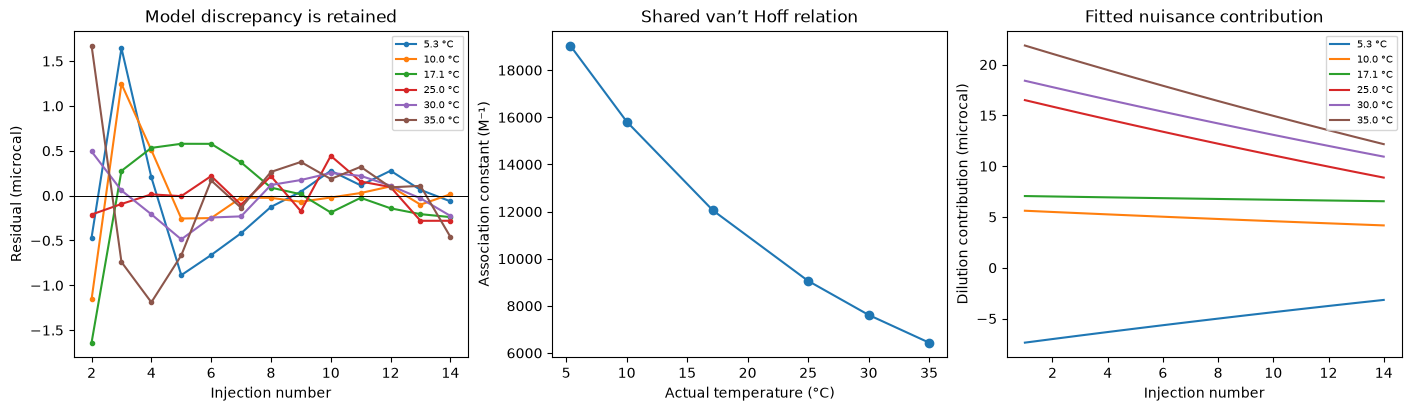

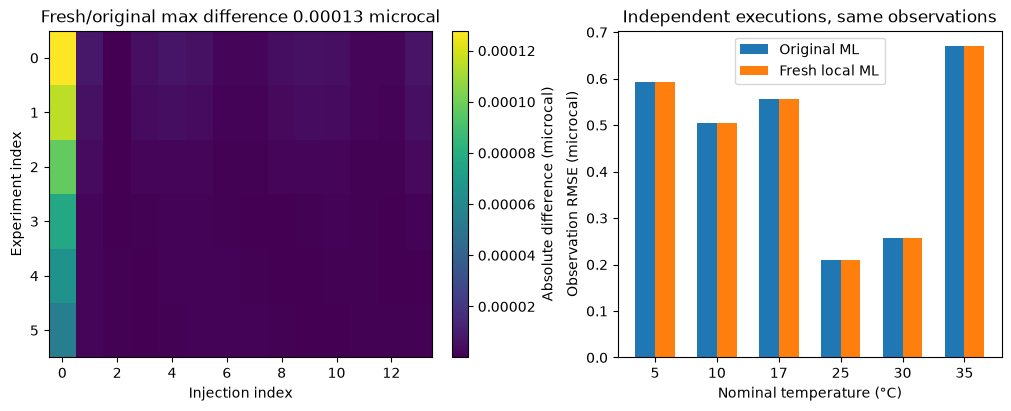

In [3]:
upstream=np.load(ROOT/'notebooks/reference_outputs/upstream_stages.npz',allow_pickle=False)
figures=make_figures(data,fit,upstream)
for fig in figures: display(fig)
plt.close('all')

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('standalone_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
ref=judge.load_arrays(ROOT/'evaluation/baseline_reference.npz')
import json
bounds=json.loads((ROOT/'evaluation/metrics.json').read_text())['boundaries']
values,passed=judge.score(fresh,ref,data['heats'][None],bounds)
print('Fresh metrics (max absolute errors in output units; RMSE in microcal):')
print(json.dumps(values,indent=2));print('All criteria passed:',passed)
assert passed
print('Residual/noise scale ratio:',values['observation_rmse']/.1)
print('The ratio above1 indicates model discrepancy beyond the arbitrary numerical weight.')

Fresh metrics (max absolute errors in output units; RMSE in microcal):
{
  "enthalpy": 0.02499307946072804,
  "association_constant": 0.02533711424075591,
  "effective_site_factor": 3.6707393342716443e-06,
  "dilution_slope": 0.3849448989094526,
  "dilution_offset": 0.0001516542012405253,
  "predicted_heats": 0.00012781348407742144,
  "observation_rmse": 0.4954062051623934
}
All criteria passed: True
Residual/noise scale ratio: 4.954062051623934
The ratio above1 indicates model discrepancy beyond the arbitrary numerical weight.


## Conclusion
The complete fresh fit reproduces the original ML thermodynamic estimator and conserves mass under the stated one-site/overflow model. It retains systematic residuals and an effective factor near1.47; these limit physical interpretation. Multi-temperature coupling supports a finite reference affinity and shared enthalpy, but no independent ground truth or posterior credibility is claimed. The original Bayesian path was intentionally not selected because the author explicitly provides ML and only that path is the bound method here.